## Exploring KP performance, Marketplace dynamics, and socioeconomic conditions across California counties

Start by loading the 3 marts from duckdb

In [1]:
import duckdb
import pandas as pd
con = duckdb.connect("../data/processed/analysis.duckdb", read_only=True)

df_socioeconomic = con.sql("select * from analysis.main_marts.mart_cty_yr_socioeconomic").df()
df_market = con.sql("select * from analysis.main_marts.mart_cty_yr_market").df()
df_performance = con.sql("select * from analysis.main_marts.mart_cty_yr_performance").df()

df_joined = (
    df_market
    .merge(
        df_performance,
        on=["county_fips", "year"],
        how="left",
        suffixes=("", "_performance")
    )
    .merge(
        df_socioeconomic,
        on=["county_fips", "year"],
        how="left",
        suffixes=("", "_socio")
    )
)

Correlation between socioeconomic / market conditions and performance

In [5]:
features = [
    # performance
    "kp_enrollment",
    "kp_market_share",
    "kp_enrollment_growth_yoy_pct",
    "marketplace_enrollment_growth_yoy_pct",

    # market
    "carrier_count",
    "plan_count",
    "silver_plan_count",
    "gold_plan_count",
    "lowest_cost_silver_premium",
    "benchmark_silver_premium",
    "kp_plan_count",

    # socioeconomic
    "population_total",
    "population_growth_yoy_pct",
    "median_household_income",
    "poverty_rate",
    "uninsured_rate",
    "labor_force_total",
    "unemployment_rate",
    "establishment_count",
    "employment_total",
    "avg_annual_pay",
    "employment_yoy_pct_change",
]

corr = df_joined[features].corr(method="pearson")
corr

,kp_enrollment,kp_market_share,kp_enrollment_growth_yoy_pct,marketplace_enrollment_growth_yoy_pct,carrier_count,plan_count,silver_plan_count,gold_plan_count,lowest_cost_silver_premium,benchmark_silver_premium,...,population_growth_yoy_pct,median_household_income,poverty_rate,uninsured_rate,labor_force_total,unemployment_rate,establishment_count,employment_total,avg_annual_pay,employment_yoy_pct_change
kp_enrollment,1.000000,0.487651,-0.020858,0.070108,0.586997,0.641153,0.676837,0.668862,-0.188315,-0.207590,...,-0.044925,0.422473,-0.258831,-0.151217,0.856940,-0.202853,0.847760,0.854906,0.462350,-0.026489
kp_market_share,0.487651,1.000000,0.016639,0.039740,0.523679,0.620126,0.580681,0.633077,-0.151365,-0.182202,...,-0.001124,0.624788,-0.448789,-0.454367,0.183760,-0.323466,0.141533,0.185864,0.545954,-0.039940
kp_enrollment_growth_yoy_pct,-0.020858,0.016639,1.000000,-0.098081,0.013377,0.008931,0.010713,0.014818,-0.037711,-0.042032,...,0.006411,-0.013578,0.015028,0.042638,-0.019962,-0.011273,-0.018400,-0.021684,-0.029770,-0.007967
marketplace_enrollment_growth_yoy_pct,0.070108,0.039740,-0.098081,1.000000,0.015922,0.012164,0.014661,0.020764,0.023146,0.149882,...,0.134496,0.031800,-0.052764,-0.080732,0.020717,0.454660,0.024708,0.009943,0.043662,-0.370206
carrier_count,0.586997,0.523679,0.013377,0.015922,1.000000,0.960032,0.947300,0.937495,-0.507711,-0.540130,...,-0.021013,0.377373,-0.168724,-0.081231,0.632652,-0.131422,0.585054,0.637651,0.388996,0.066218
plan_count,0.641153,0.620126,0.008931,0.012164,0.960032,1.000000,0.992068,0.988313,-0.418882,-0.454128,...,-0.021353,0.453801,-0.249946,-0.207401,0.648512,-0.207919,0.609405,0.651102,0.416521,0.025212
silver_plan_count,0.676837,0.580681,0.010713,0.014661,0.947300,0.992068,1.000000,0.989185,-0.419633,-0.453163,...,-0.022038,0.445875,-0.239653,-0.181891,0.707166,-0.213405,0.665485,0.708203,0.412894,0.017420
gold_plan_count,0.668862,0.633077,0.014818,0.020764,0.937495,0.988313,0.989185,1.000000,-0.418428,-0.451042,...,-0.019022,0.473609,-0.250383,-0.235669,0.669411,-0.199274,0.625578,0.670816,0.433843,0.007932
lowest_cost_silver_premium,-0.188315,-0.151365,-0.037711,0.023146,-0.507711,-0.418882,-0.419633,-0.418428,1.000000,0.956148,...,-0.037803,0.145728,-0.256415,-0.315963,-0.408748,-0.139145,-0.367267,-0.373315,0.080605,-0.084983
benchmark_silver_premium,-0.207590,-0.182202,-0.042032,0.149882,-0.540130,-0.454128,-0.453163,-0.451042,0.956148,1.000000,...,-0.012822,0.120763,-0.208648,-0.350159,-0.428625,-0.054877,-0.391037,-0.396744,0.077278,-0.111867


## Notes
- Analysis is 2016-2024
- Use kp_offered to describe where KP offers plans, kp_enrollment will not correspond to this – plan clients may live in places where kp doesn't offer

## Kaiser share on the service-area footprint

These ranks use counties where Kaiser is for sale (`kp_offered`). The pooled correlation above mixes county size into enrollment and treats every county-year as its own market.

The 2025 tables cover the 33 offered counties. Statewide enrollment sums every county. Median share uses offered counties only. The dashed line at 2025 marks Monterey joining the service area.

In [2]:
from IPython.display import HTML, Markdown, display

snap = df_joined[(df_joined["year"] == 2025) & df_joined["kp_offered"]].copy()


def rank_counties(frame, by):
    ranked = frame.sort_values(by, ascending=False).reset_index(drop=True)
    ranked.insert(0, "rank", range(1, len(ranked) + 1))
    ranked["county"] = ranked["county_name"].str.replace(" County", "", regex=False)
    ranked["enrollment"] = ranked["kp_enrollment"].map(lambda value: f"{value:,.0f}")
    ranked["share_pct"] = (ranked["kp_market_share"] * 100).map(lambda value: f"{value:.1f}")
    return ranked[["rank", "county", "enrollment", "share_pct"]]


display(Markdown("**2025 Kaiser share, offered counties**"))
display(HTML(rank_counties(snap, "kp_market_share").to_html(index=False)))
display(Markdown("**2025 Kaiser enrollment, offered counties**"))
display(HTML(rank_counties(snap, "kp_enrollment").to_html(index=False)))

**2025 Kaiser share, offered counties**

rank,county,enrollment,share_pct
1,Solano,"12,110",80.4
2,Alameda,"66,450",79.8
3,Contra Costa,"45,670",77.4
4,San Mateo,"24,380",73.0
5,San Joaquin,"31,130",72.9
6,Sonoma,"18,150",69.9
7,Napa,"4,480",69.5
8,Santa Cruz,"10,270",68.2
9,Sacramento,"41,490",60.7
10,Stanislaus,"14,430",59.7


**2025 Kaiser enrollment, offered counties**

rank,county,enrollment,share_pct
1,Los Angeles,"132,200",23.5
2,Alameda,"66,450",79.8
3,Contra Costa,"45,670",77.4
4,Orange,"44,730",24.5
5,Santa Clara,"44,410",54.8
6,Sacramento,"41,490",60.7
7,San Joaquin,"31,130",72.9
8,San Diego,"29,990",20.1
9,San Mateo,"24,380",73.0
10,San Francisco,"22,590",58.3


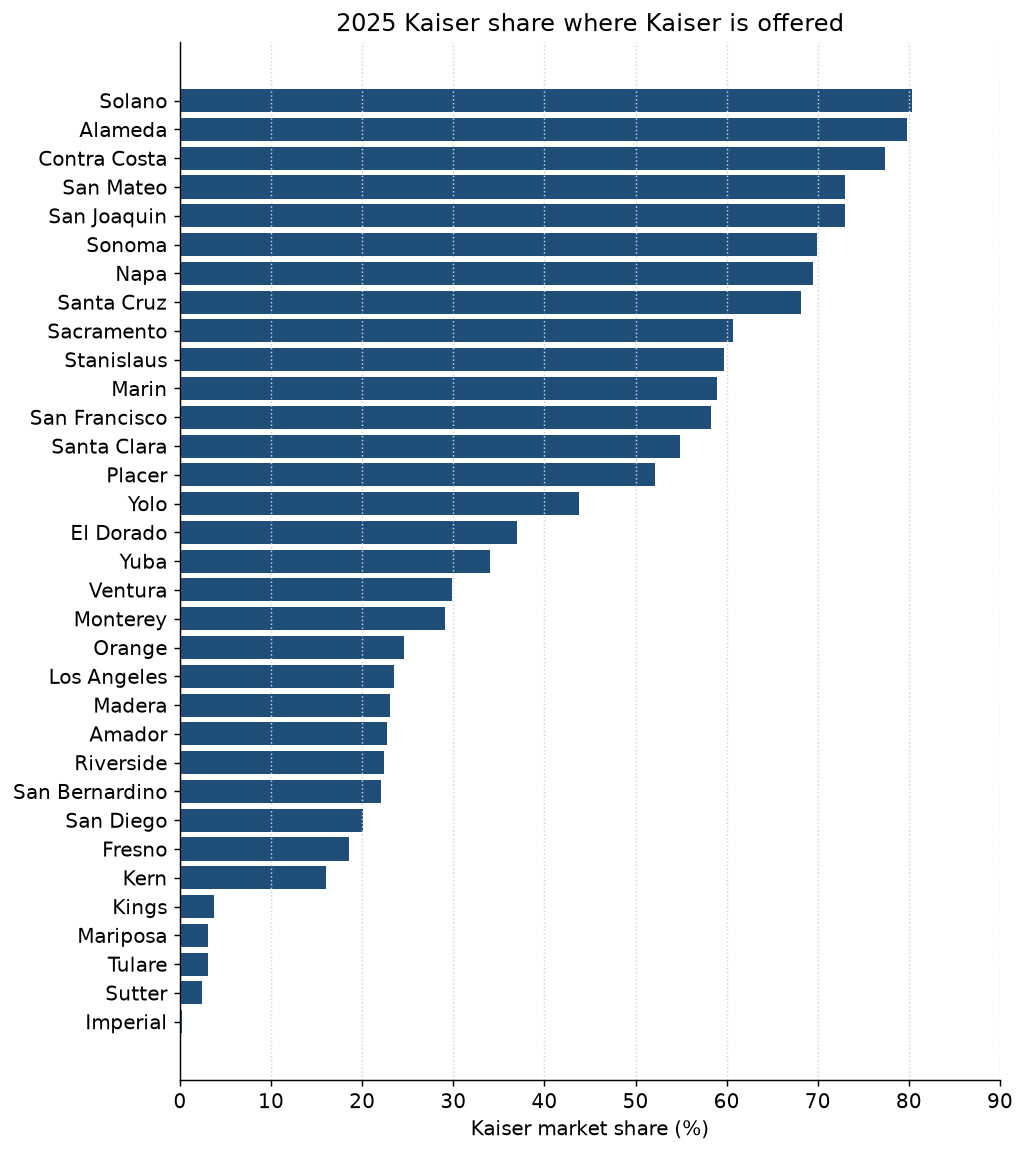

In [3]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 11,
})

share_order = snap.sort_values("kp_market_share", ascending=True)
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(
    share_order["county_name"].str.replace(" County", "", regex=False).tolist(),
    (share_order["kp_market_share"] * 100).tolist(),
    color="#1f4e79",
)
ax.set_xlabel("Kaiser market share (%)")
ax.set_xlim(0, 90)
ax.set_title("2025 Kaiser share where Kaiser is offered")
ax.grid(axis="x", linestyle=":", color="#d0d5dd")
fig.tight_layout()

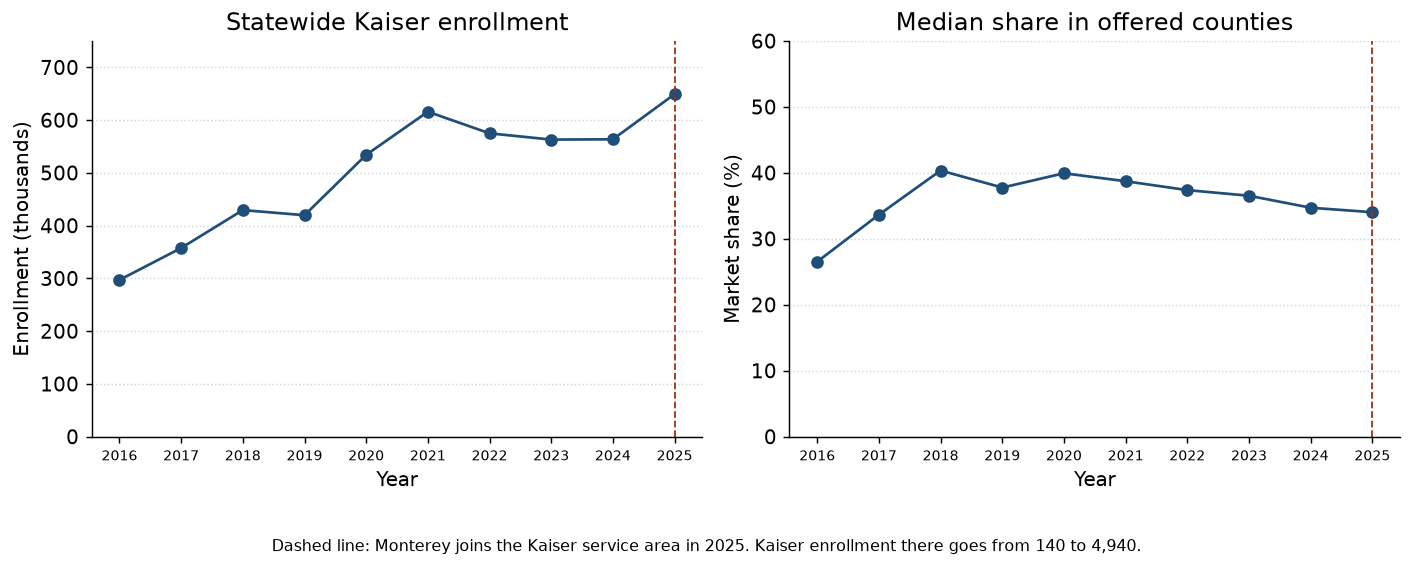

In [4]:
performance = df_joined[df_joined["year"].between(2016, 2025)].copy()
performance["year"] = performance["year"].astype(int)

statewide = performance.groupby("year")["kp_enrollment"].sum().sort_index()
median_share = (
    performance.loc[performance["kp_offered"]]
    .groupby("year")["kp_market_share"]
    .median()
    .sort_index()
)
monterey = (
    performance.loc[performance["county_name"].eq("Monterey County")]
    .set_index("year")
    .sort_index()
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True)
years = statewide.index.tolist()

axes[0].plot(years, statewide.to_numpy() / 1000, marker="o", color="#1f4e79")
axes[0].set_title("Statewide Kaiser enrollment")
axes[0].set_ylabel("Enrollment (thousands)")
axes[0].set_ylim(0, 750)

axes[1].plot(years, median_share.to_numpy() * 100, marker="o", color="#1f4e79")
axes[1].set_title("Median share in offered counties")
axes[1].set_ylabel("Market share (%)")
axes[1].set_ylim(0, 60)

for ax in axes:
    ax.axvline(2025, color="#9a3412", linestyle="--", linewidth=1)
    ax.set_xlabel("Year")
    ax.set_xticks(years)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="y", linestyle=":", color="#d0d5dd")

note = (
    "Dashed line: Monterey joins the Kaiser service area in 2025. "
    f"Kaiser enrollment there goes from {monterey.loc[2024, 'kp_enrollment']:,.0f} "
    f"to {monterey.loc[2025, 'kp_enrollment']:,.0f}."
)
fig.tight_layout()
fig.subplots_adjust(bottom=0.22)
fig.text(0.5, 0.02, note, ha="center", fontsize=9)

## Associations across offered counties

One row per county Kaiser offered in 2016–2024. Each value is the mean of the years that county was on the footprint. Monterey is not in this panel; it joins in 2025.

The level outcome is `kp_market_share`. Predictors are income, poverty, the uninsured rate, unemployment, carrier count, and the two Silver premiums. Los Angeles is left out of the premium correlations because that county has no single premium. Population, labor force, employment, and establishment count are left out. Those series track county size, which is what drove the enrollment correlations in the pooled matrix.

Change over time is the mean of `kp_market_share_change_yoy_pp` in years when prior Kaiser enrollment is at least 100. Imperial and Mariposa never clear that floor. `kp_enrollment_growth_yoy_pct` is not used.

In [5]:
PREDICTORS = [
    ("median_household_income", "Median household income"),
    ("poverty_rate", "Poverty rate"),
    ("uninsured_rate", "Uninsured rate"),
    ("unemployment_rate", "Unemployment rate"),
    ("carrier_count", "Carrier count"),
    ("lowest_cost_silver_premium", "Lowest-cost Silver premium"),
    ("benchmark_silver_premium", "Benchmark Silver premium"),
]
PREMIUM_COLUMNS = {"lowest_cost_silver_premium", "benchmark_silver_premium"}
PRIOR_ENROLLMENT_FLOOR = 100

panel = df_joined.sort_values(["county_fips", "year"]).copy()
panel["prior_kp_enrollment"] = panel.groupby("county_fips")["kp_enrollment"].shift(1)

offered_history = panel[panel["kp_offered"] & panel["year"].between(2016, 2024)].copy()
measure_cols = ["kp_market_share", *[column for column, _label in PREDICTORS]]
county = offered_history.groupby(["county_fips", "county_name"], as_index=False)[measure_cols].mean()

change_rows = offered_history[
    offered_history["prior_kp_enrollment"].ge(PRIOR_ENROLLMENT_FLOOR)
    & offered_history["kp_market_share_change_yoy_pp"].notna()
]
share_change = change_rows.groupby("county_fips", as_index=False)["kp_market_share_change_yoy_pp"].mean()
county = county.merge(share_change, on="county_fips", how="left")


def correlation_table(frame, outcome):
    rows = []
    for column, label in PREDICTORS:
        sample = frame.loc[~frame["county_name"].eq("Los Angeles County")] if column in PREMIUM_COLUMNS else frame
        pair = sample[[outcome, column]].dropna()
        rows.append({
            "predictor": label,
            "n": len(pair),
            "pearson": pair[outcome].corr(pair[column], method="pearson"),
            "spearman": pair[outcome].corr(pair[column], method="spearman"),
        })
    table = pd.DataFrame(rows)
    table[["pearson", "spearman"]] = table[["pearson", "spearman"]].round(2)
    return table


below_floor = county.loc[county["kp_market_share_change_yoy_pp"].isna(), "county_name"]
print(
    "No year with prior Kaiser enrollment of at least "
    f"{PRIOR_ENROLLMENT_FLOOR}: "
    + ", ".join(below_floor.str.replace(" County", "", regex=False))
)

display(Markdown("**Kaiser market share, county means**"))
display(HTML(correlation_table(county, "kp_market_share").to_html(index=False)))
display(Markdown("**Year-to-year share change, where prior enrollment is at least 100**"))
display(HTML(correlation_table(county, "kp_market_share_change_yoy_pp").to_html(index=False)))

No year with prior Kaiser enrollment of at least 100: Imperial, Mariposa


**Kaiser market share, county means**

predictor,n,pearson,spearman
Median household income,32,0.62,0.65
Poverty rate,32,-0.58,-0.55
Uninsured rate,32,-0.65,-0.57
Unemployment rate,32,-0.58,-0.60
Carrier count,32,0.04,0.12
Lowest-cost Silver premium,31,0.61,0.60
Benchmark Silver premium,31,0.52,0.49


**Year-to-year share change, where prior enrollment is at least 100**

predictor,n,pearson,spearman
Median household income,30,0.54,0.59
Poverty rate,30,-0.59,-0.55
Uninsured rate,30,-0.59,-0.59
Unemployment rate,30,-0.51,-0.49
Carrier count,30,-0.14,-0.09
Lowest-cost Silver premium,29,0.68,0.69
Benchmark Silver premium,29,0.67,0.62


## Relationships that hold

Share moves with income (Spearman 0.65) and against poverty (−0.55), the uninsured rate (−0.57), and unemployment (−0.60). Carrier count does not (Spearman 0.12), so it is not plotted.

The benchmark Silver premium also moves with share (Spearman 0.49), with Los Angeles left out. The lowest-cost Silver premium moves with share in the same direction (Spearman 0.60). The chart shows the benchmark.

Share changes follow the same pattern. Where prior enrollment is at least 100, share rose by about 1.4 percentage points a year on average.

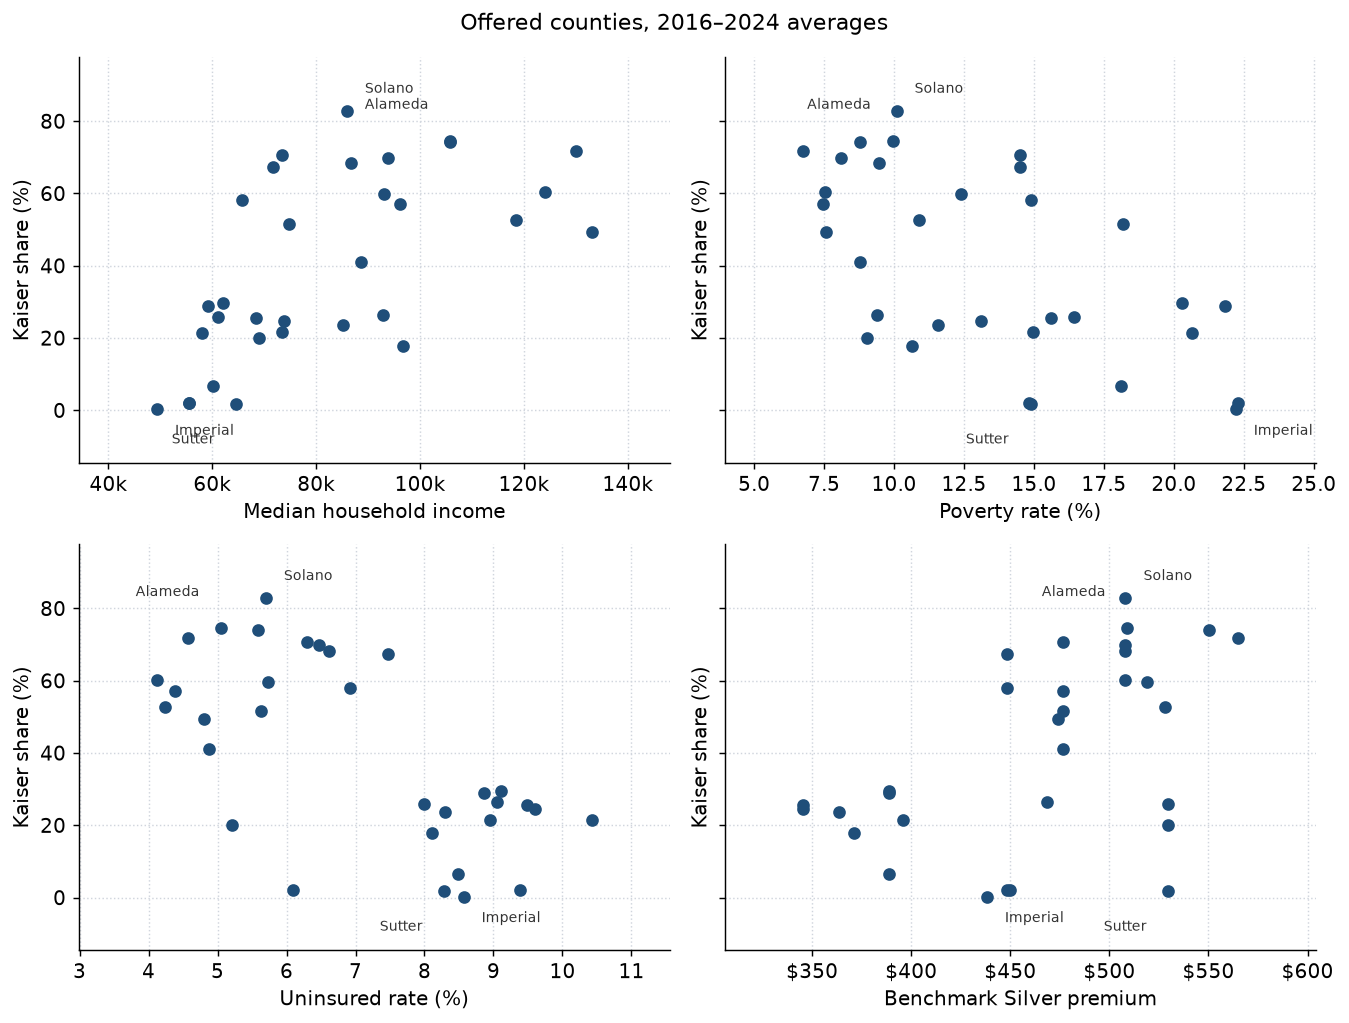

In [6]:
import matplotlib.ticker as mticker

scatter = county.copy()
scatter["county"] = scatter["county_name"].str.replace(" County", "", regex=False)
scatter["share_pct"] = scatter["kp_market_share"] * 100
scatter_panels = [
    (scatter, "median_household_income", "Median household income"),
    (scatter, "poverty_rate", "Poverty rate (%)"),
    (scatter, "uninsured_rate", "Uninsured rate (%)"),
    (
        scatter.loc[~scatter["county_name"].eq("Los Angeles County")],
        "benchmark_silver_premium",
        "Benchmark Silver premium",
    ),
]


def label_extremes(ax, data, x):
    groups = (
        (data.nlargest(2, "share_pct"), 8, "bottom"),
        (data.nsmallest(2, "share_pct"), -8, "top"),
    )
    for rows, offset_y, valign in groups:
        picks = rows.drop_duplicates("county_fips")
        for step, (_, row) in enumerate(picks.iterrows()):
            ax.annotate(
                row["county"],
                (row[x], row["share_pct"]),
                textcoords="offset points",
                xytext=(
                    10 if step == 0 else -12,
                    offset_y if step == 0 else offset_y * 2,
                ),
                ha="left" if step == 0 else "right",
                va=valign,
                fontsize=8,
                color="#333333",
            )


fig, axes = plt.subplots(2, 2, figsize=(10.5, 8), sharey=True)
for ax, (data, column, label) in zip(axes.ravel(), scatter_panels):
    ax.scatter(data[column], data["share_pct"], s=36, color="#1f4e79", zorder=3)
    label_extremes(ax, data, column)
    ax.set_xlabel(label)
    ax.set_ylabel("Kaiser share (%)")
    ax.margins(0.18)
    ax.grid(linestyle=":", color="#d0d5dd")

axes[0, 0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _pos: f"{value / 1000:.0f}k"))
axes[1, 1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _pos: f"${value:.0f}"))
fig.suptitle("Offered counties, 2016–2024 averages", fontsize=12)
fig.tight_layout()